## Import the libraries ##


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


## Load the dataset ##

In [20]:
data_path = "../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [21]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Understand the dataset structure ##

### Dataset dimensions ###

In [22]:
df.shape

(7043, 21)

### Column names ###

In [23]:
df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

### Data types and non-null counts ###

In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### Statistical summary ###

In [25]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Missing values ###

In [26]:
df.isnull().sum().sort_values(ascending=False)

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## Investigating our target variable: Churn ##

In [27]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

### percentages: ###

In [28]:
df['Churn'].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

TotalCharges -> it's data type is str, eventhough it represents a monetary amount.

that means we need to investigate it before modeling.


## Investigate data quality ##

### Check for blank strings ###

In [29]:
df['TotalCharges'].value_counts().head()

TotalCharges
20.2     11
         11
19.75     9
19.9      8
20.05     8
Name: count, dtype: int64

In [30]:
blank_total_charges = df['TotalCharges'].str.strip().eq('').sum()

print("Blank TotalCharges values:", blank_total_charges)

Blank TotalCharges values: 11


### Inspect those records ###

In [31]:
df[df['TotalCharges'].str.strip().eq('')][
    ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


those 11 customers have tenure = 0. This is a useful observation: they appear to be new customers who have not yet accumulated any tenure.

We should not automatically remove these customers. They are still valid customers and could be important for predicting early churn.

All 11 customers with blank TotalCharges have Churn = No.

Churn = No means they are classified as customers who have not churned in this dataset.

### Check duplicate customers ###


In [32]:
print("Duplicate customer IDs:", df['customerID'].duplicated().sum())

Duplicate customer IDs: 0


### Check the target distribution visually ###

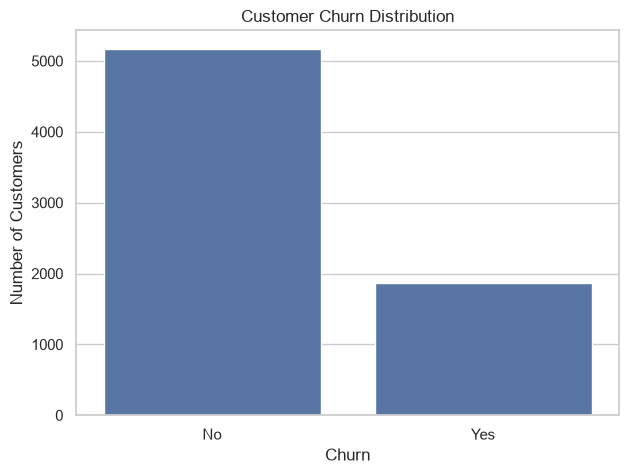

In [33]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')

plt.show()

A useful Data Science concept: Baseline accuracy
Before training any model, let's calculate the accuracy of a very simple prediction strategy: predict that every customer will stay.

In [34]:
baseline_accuracy = (df['Churn'] == 'No').mean()

print(f"Baseline Accuracy: {baseline_accuracy:.2%}")

Baseline Accuracy: 73.46%


This is called a majority-class baseline.

It helps us understand why accuracy alone can be misleading. A machine learning model should do more than predict the majority class; it should identify customers who are actually at risk of leaving.


In [35]:
df[df['TotalCharges'].isnull()]['Churn'].value_counts()

Series([], Name: count, dtype: int64)

In [36]:
df[df['TotalCharges'].isnull()]['tenure'].value_counts()

Series([], Name: count, dtype: int64)

The reason to got "No rows to show" is that the blank values are actually empty strings or whitespace, not NaN.

That's exactly why our initial check returned zero missing values.

Let's verify this using the original data, without cleaning anything.

In [37]:
blank_rows = df[df['TotalCharges'].str.strip() == '']

blank_rows[
    ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [38]:
blank_rows['Churn'].value_counts()

Churn
No    11
Name: count, dtype: int64

In [39]:
blank_rows['tenure'].value_counts()

tenure
0    11
Name: count, dtype: int64

We have identified the 11 blank values.

## Clean the `TotalCharges` column

TotalCharges is currently a string column. We need to convert it to a numeric column so we can perform calculations and use it in machine learning.

We'll:
1. Replace blank strings with missing values (NaN).
2. Convert the column to numeric.
3. Check whether any missing values remain.
4. Handle the 11 new customers.

### Replace blank strings with NaN ###

In [40]:
df['TotalCharges'] = df['TotalCharges'].str.strip().replace('', np.nan)

.str.strip() removes unnecessary whitespace.

.replace('', np.nan) converts empty strings into proper missing values.

### Converts the column into numeric format ###

In [42]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

Now Pandas can treat `TotalCharges` as numerical data rather than text.

### Verify Missing Values ###

In [43]:
print("Missing values:", df['TotalCharges'].isnull().sum())
print("Data type:", df['TotalCharges'].dtype)

Missing values: 11
Data type: float64


### Handle the missing values ###

In [44]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)

We use 0 because the 11 affected customers have zero tenure, meaning they have not accumulated charges in the dataset.

### Final verification ###

In [45]:
print("Missing values:", df['TotalCharges'].isnull().sum())
print("Zero TotalCharges:", (df['TotalCharges'] == 0).sum())
print("Data type:", df['TotalCharges'].dtype)

Missing values: 0
Zero TotalCharges: 11
Data type: float64


## Verify the overall dataset ##

Before moving into EDA, making sure the entire dataset is in good condition.

### Check dataset dimensions ###

In [46]:
print("Dataset shape:", df.shape)

Dataset shape: (7043, 21)


### Check all missing values ###

In [47]:
df.isnull().sum().sort_values(ascending=False)

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

### Check data types ###

In [48]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## Exploratory Data Analysis (EDA)

### Understaand the target variable ###

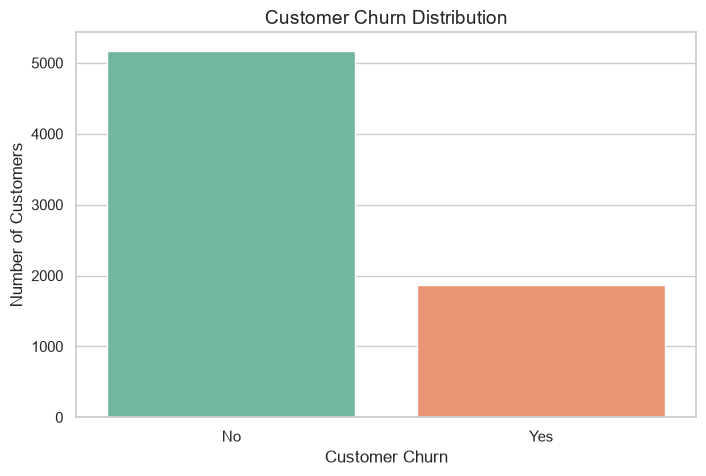

In [49]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Churn',
    hue='Churn',
    palette='Set2',
    legend=False
)

plt.title('Customer Churn Distribution', fontsize=14)
plt.xlabel('Customer Churn')
plt.ylabel('Number of Customers')

plt.show()

In [50]:
churn_percentage = df['Churn'].value_counts(normalize=True) * 100

print(churn_percentage)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


### Understand the business meaning ###

- 73.46% of customers stayed.
- 26.54% of customers churned.
This tells us that the dataset has an unequal distribution of target classes.

Concept: Class imbalance

Class imbalance occurs when one target category has significantly more observations than another.

Why does this matter?

Imagine building a model that predicts every customer as No.

It would achieve 73.46% accuracy, but it would fail to identify every customer who leaves.

That's why we'll eventually pay particular attention to recall, precision, F1-score, and PR-AUC.

### Investigate churn by contract type ###

We want to understand whether customers with different contract types have different churn rates.

In [51]:
df['Contract'].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

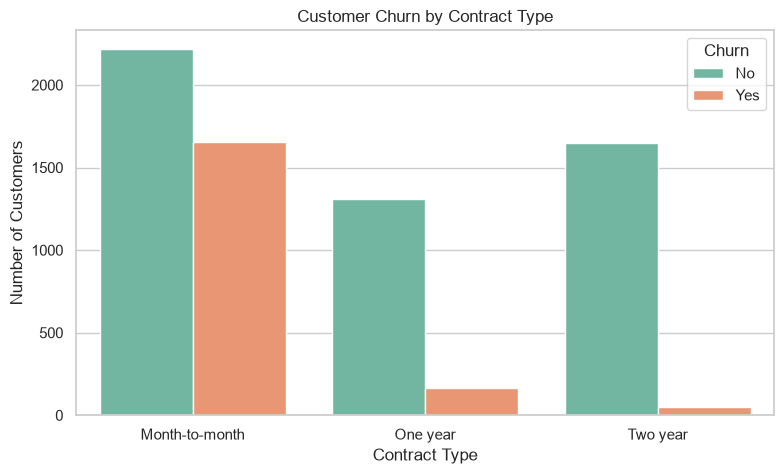

In [52]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='Contract',
    hue='Churn',
    palette='Set2'
)

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')

plt.show()

In [53]:
contract_churn = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


- Month-to-month customers have the highest churn rate.
- One-year contract customers are much less likely to churn.
- Two-year contract customers have the lowest churn rate.

However, this is observational data. We cannot conclude that longer contracts alone cause customers to stay. Other factors, such as tenure, pricing, and customer satisfaction may also be related.


### Business Insight 1: Contract Type and Customer Churn

The analysis shows a strong association between contract type and customer churn. Month-to-month customers have a churn rate of 42.71%, while one-year and two-year contract customers have churn rates of 11.27% and 2.83%, respectively.

This suggests that customers with shorter contract commitments may be at a higher risk of leaving. The company could focus on understanding the reasons for month-to-month customer churn and consider retention strategies such as loyalty benefits or suitable long-term contract offers.

However, contract type alone may not explain churn. Further analysis is required to investigate other customer characteristics.

### Investigate churn by customer tenure


Are customers who have been with the company for a shorter period more likely to churn?

`tenure` represents the number of months a customer has stayed with the company.

#### `tenure` distribution by `churn`


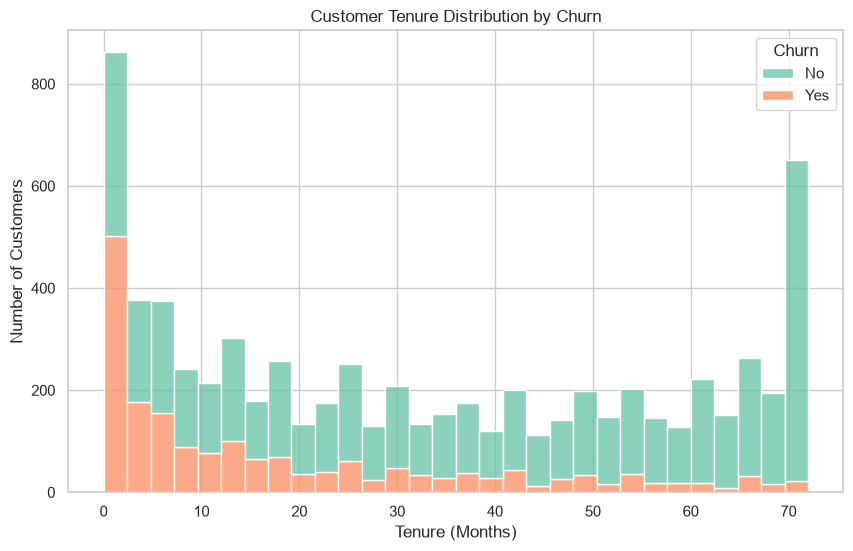

In [54]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='tenure',
    hue='Churn',
    bins=30,
    multiple='stack',
    palette='Set2'
)

plt.title('Customer Tenure Distribution by Churn')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')

plt.show()

#### Compare tenure for churned and retained customers

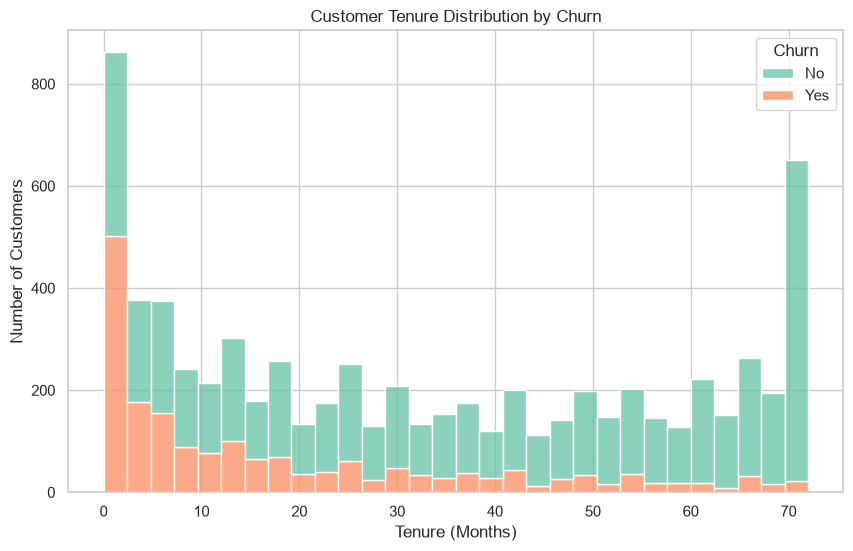

In [55]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='tenure',
    hue='Churn',
    bins=30,
    multiple='stack',
    palette='Set2'
)

plt.title('Customer Tenure Distribution by Churn')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')

plt.show()

#### Calculate the average tenure

In [56]:
tenure_summary = df.groupby('Churn')['tenure'].agg(
    ['mean', 'median', 'min', 'max']
)

tenure_summary

,mean,median,min,max
Churn,,,,
No,37.569965,38.0,0,72
Yes,17.979133,10.0,1,72


### Business Insight 2: Customer Tenure and Churn

The analysis indicates that churned customers have considerably shorter tenures than retained customers. The average tenure of churned customers is 17.98 months, compared with 37.57 months for customers who stayed. The median tenure is 10 months for churned customers and 38 months for retained customers.

This suggests that customer retention efforts may be particularly important during the early stages of the customer relationship. The company could investigate early customer experiences and identify potential service or billing issues that may contribute to churn.

### Investigate monthly charges

Are customers paying higher monthly charges more likely to churn?


In [57]:
monthly_charges_summary = df.groupby('Churn')['MonthlyCharges'].agg(
    ['mean', 'median', 'min', 'max']
)

monthly_charges_summary

,mean,median,min,max
Churn,,,,
No,61.265124,64.425,18.25,118.75
Yes,74.441332,79.650,18.85,118.35


Customers who churned paid approximately Rs. 13.18 more per month on average than customers who stayed.

This suggests that higher monthly charges may be associated with churn.

However, higher charges may also reflect customers using more services. We should investigate service types before concluding that price is the main reason.

#### Analyze churn by monthly charge groups

I'll divide customers into four groups based on their monthly charges.


In [58]:
df['MonthlyChargeGroup'] = pd.qcut(
    df['MonthlyCharges'],
    q=4,
    duplicates='drop'
)

monthly_churn = pd.crosstab(
    df['MonthlyChargeGroup'],
    df['Churn'],
    normalize='index'
) * 100

monthly_churn

Churn,No,Yes
MonthlyChargeGroup,,
"(18.249, 35.5]",88.762770,11.237230
"(35.5, 70.35]",75.424689,24.575311
"(70.35, 89.85]",62.492886,37.507114
"(89.85, 118.75]",67.121729,32.878271


The churn rate rises as monthly charges increase through the first three groups. However, the highest-charge group has a lower churn rate than the third group.

This is an important observation: the relationship between monthly charges and churn is not simply "the higher the price, the higher the churn."

The highest-paying customers may have different service packages, contracts, or customer characteristics.

### Business Insight 3: Monthly Charges and Customer Churn

Churned customers have higher average monthly charges (Rs. 74.44) compared with retained customers (Rs. 61.27). The churn rate increases from 11.24% in the lowest monthly charge group to 37.51% in the third group.

However, the highest monthly charge group has a churn rate of 32.88%, indicating that the relationship is not strictly linear. Other factors, such as contract type and service combinations, may also influence customer churn.

Further investigation is required to understand the relationship between pricing and customer retention.

### Investigate payment methods and internet services

Are certain payment methods associated with higher churn?
Does the type of internet service relate to customer churn?

these are useful categorical features to investigate before modeling.

#### Churn by payment method

In [59]:
payment_churn = pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize='index'
) * 100

payment_churn.round(2)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


Customers using electronic checks have a churn rate of45.29%, considerably higher than customers using automatic payment methods.

Automatic credit card payments have the lowest churn rate at 15.24%.

This could indicate a relationship between payment convenience, billing preferences, and customer retention. However, payment method may also be associated with other features such as contract type or tenure.

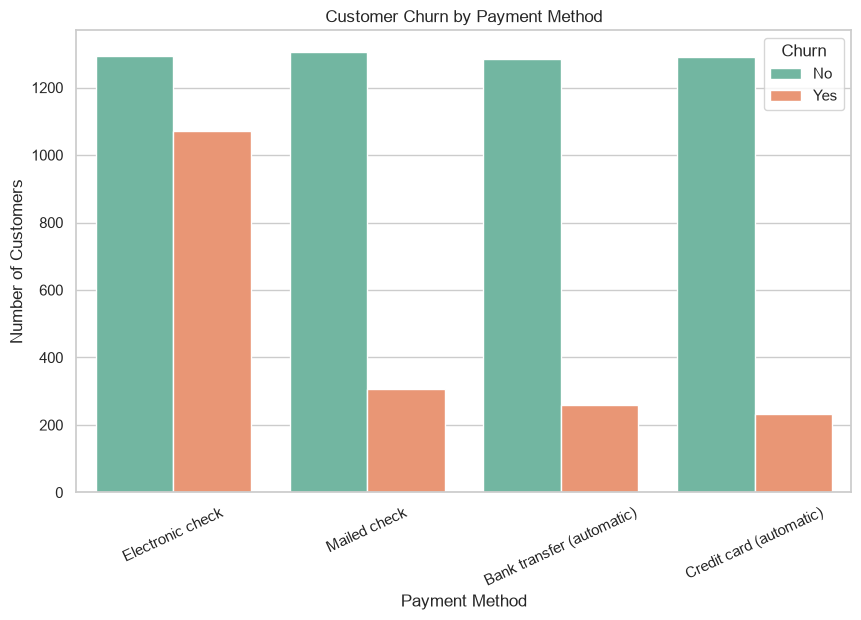

In [60]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x='PaymentMethod',
    hue='Churn',
    palette='Set2'
)

plt.title('Customer Churn by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Customers')
plt.xticks(rotation=25)

plt.show()

#### Churn by internet service

In [61]:
internet_churn = pd.crosstab(
    df['InternetService'],
    df['Churn'],
    normalize='index'
) * 100

internet_churn.round(2)

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


Fibre optic customers have a churn rate of 42.89%.
DSL customers have a churn rate of 18.96%.
customers without internet service have a churn rate of 7.04%.

The fibre optic churn rate is more than twice the DSL churn rate.

This is an interesting finding. Fibre optic service may be associated with higher charges, service expectations, or other customer characteristics. Also shouldnt assume the technology itself is causing churn.

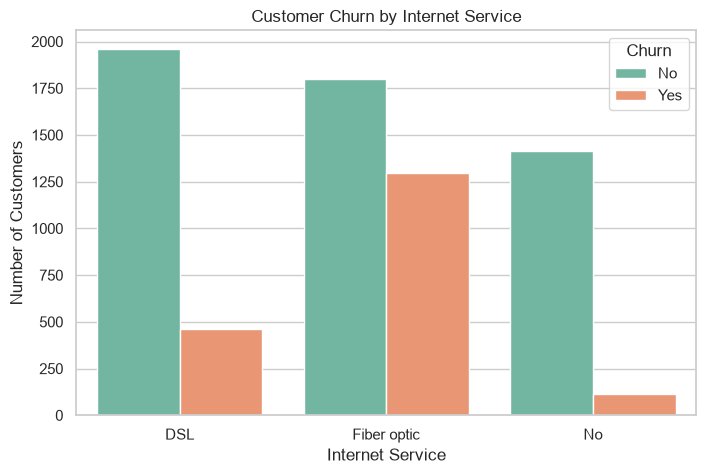

In [62]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='InternetService',
    hue='Churn',
    palette='Set2'
)

plt.title('Customer Churn by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Number of Customers')

plt.show()

### Business Insight 4: Payment Method and Customer Churn

Customers using electronic checks have the highest churn rate at 45.29%. In comparison, customers using automatic bank transfers and credit card payments have churn rates of 16.71% and 15.24%, respectively.

This indicates a strong association between payment method and customer churn. The company could investigate whether electronic check users experience billing difficulties or have different customer characteristics. Encouraging convenient payment options may be worth exploring as a retention strategy.

### Business Insight 5: Internet Service and Customer Churn

Fiber optic customers have a churn rate of 41.89%, compared with 18.96% for DSL customers and 7.40% for customers without internet service.

The higher churn rate among fiber optic customers suggests that this customer group requires further investigation. Possible factors include pricing, service expectations, contract type, and customer experience. Additional analysis is required before identifying the underlying reasons for this pattern.

### Investigate customer services


Are  customers who lack support services more lickely to churn?

In [63]:
support_churn = pd.crosstab(
    df['TechSupport'],
    df['Churn'],
    normalize='index'
) * 100

support_churn.round(2)

Churn,No,Yes
TechSupport,,
No,58.36,41.64
No internet service,92.60,7.40
Yes,84.83,15.17


Customers without tech support have a much higher churn rate (41.64%) than customers who have tech support (15.17%).

In [64]:
security_churn = pd.crosstab(
    df['OnlineSecurity'],
    df['Churn'],
    normalize='index'
) * 100

security_churn.round(2)

Churn,No,Yes
OnlineSecurity,,
No,58.23,41.77
No internet service,92.60,7.40
Yes,85.39,14.61


The same pattern appears here. Customers without online security have a higher churn rate (41.77%) than those who have the service (14.61%).

### Tech Support and Online Security Analysis

The analysis shows that customers without tech support have a
churn rate of 41.64%, compared with 15.17% among customers who
have tech support.

Similarly, customers without online security have a churn rate
of 41.77%, while customers who have online security have a
churn rate of 14.61%.

These findings suggest that TechSupport and OnlineSecurity
could be important features for predicting customer churn.

### Investigate `SeniorCitizen`

In [65]:
senior_churn = pd.crosstab(
    df['SeniorCitizen'],
    df['Churn'],
    normalize='index'
) * 100

senior_churn.round(2)

Churn,No,Yes
SeniorCitizen,,
0,76.39,23.61
1,58.32,41.68


- Non-senior customers have a churn rate of 23.61%.
- Senior customers have a churn rate of 41.68%.
- The churn rate amaong senior customers is considerably higher.

### Senior Citizen Analysis

The analysis shows that senior citizens have a churn rate of
41.68%, compared with 23.61% among non-senior citizens.

This indicates that senior customers in this dataset are more
likely to churn. Therefore, SeniorCitizen may be an important
feature for customer churn prediction.

### EDA Progress

| Feature | Key observation |
|---|---|
| Contract | Month-to-month customers have 42.71% churn. |
| Tenure | Churned customers have a lower average tenure of 17.98 months. |
| Monthly Charges | Churned customers have higher average monthly charges. |
| Payment Method | Electronic check customers have 45.29% churn. |
| Internet Service | Fiber optic customers have 41.89% churn. |
| Tech Support | Customers without tech support have 41.64% churn. |
| Online Security | Customers without online security have 41.77% churn. |
| Senior Citizen | Senior customers have 41.68% churn. |

In [66]:
df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn',
 'MonthlyChargeGroup']

This dataframe has 22 columns. I'll remove 2 columns that we don't need for modeling.

- `customerID` - unique identifier, not a useful customer behaviour feature.
- `MonthlyChargeGroup` - created only for EDA, will use the original `MonthlyCharges` instead.

#### Create X and y

In [67]:
# Remove columns that are not needed for modeling
df_model = df.drop(columns=['customerID', 'MonthlyChargeGroup'])

# Separate features and target
X = df_model.drop(columns=['Churn'])
y = df_model['Churn']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7043, 19)
y shape: (7043,)


- X contains 19 input features for 7043 customers.
- y contains the churn outcome for those same customers.

#### Check the feature types

In [68]:
X.dtypes

gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
dtype: object